# Stage 3 — Unsupervised Clustering and Model Evaluation

## 1. Objective

Investigate whether meaningful research themes can be identified in arXiv NLP publications (filtered by cs.CL category and 2021–2025 years) using unsupervised clustering of titles and abstracts.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
import joblib

artifact_dir = Path("artifacts")

X_tfidf = sparse.load_npz(
    artifact_dir / "tfidf_10k_unigram_bigram.npz"
)

vectorizer = joblib.load(
    artifact_dir / "tfidf_10k_vectorizer.joblib"
)

metadata = pd.read_csv(
    artifact_dir / "document_metadata.csv",
    dtype={"id": str}
)

feature_names = vectorizer.get_feature_names_out()

print("Matrix:", X_tfidf.shape)
print("Format:", X_tfidf.getformat())
print("Metadata records:", len(metadata))
print("Vocabulary size:", len(feature_names))

assert X_tfidf.shape == (len(metadata), len(feature_names))

Matrix: (75110, 10000)
Format: csr
Metadata records: 75110
Vocabulary size: 10000


## 2. KMeans, exploratory starting point

In [3]:
from sklearn.cluster import KMeans
from time import perf_counter

# Exploratory baseline, a starting point, not the final number of research themes
k = 10

kmeans = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=3,
    max_iter=100,
    random_state=42
)

start = perf_counter()
kmeans.fit(X_tfidf)
elapsed = perf_counter() - start

# Basic diagnostics
cluster_sizes = np.bincount(
    kmeans.labels_,
    minlength=k
)

print(f"Number of clusters: {k}")
print(f"Fitting time: {elapsed:.2f} seconds")
print(f"Iterations: {kmeans.n_iter_}")
print(f"Inertia: {kmeans.inertia_:.2f}")

print("\nCluster sizes:")
for cluster_id, size in enumerate(cluster_sizes):
    print(
        f"Cluster {cluster_id}: "
        f"{size:,} papers "
        f"({size / len(metadata) * 100:.1f}%)"
    )

Number of clusters: 10
Fitting time: 8.09 seconds
Iterations: 39
Inertia: 71273.05

Cluster sizes:
Cluster 0: 2,124 papers (2.8%)
Cluster 1: 9,965 papers (13.3%)
Cluster 2: 4,290 papers (5.7%)
Cluster 3: 23,171 papers (30.8%)
Cluster 4: 4,876 papers (6.5%)
Cluster 5: 4,053 papers (5.4%)
Cluster 6: 2,798 papers (3.7%)
Cluster 7: 3,923 papers (5.2%)
Cluster 8: 4,767 papers (6.3%)
Cluster 9: 15,143 papers (20.2%)


In [4]:
# Select the two largest clusters and the smallest cluster
largest_clusters = np.argsort(cluster_sizes)[-2:][::-1]
smallest_cluster = np.argmin(cluster_sizes)

clusters_to_inspect = [
    *largest_clusters,
    smallest_cluster
]

for c in clusters_to_inspect:
    center = kmeans.cluster_centers_[c]

    # Highest-weighted features in the centroid
    top_indices = np.argsort(center)[-12:][::-1]
    top_terms = feature_names[top_indices]

    # Documents assigned to this cluster
    members = np.flatnonzero(kmeans.labels_ == c)

    # Find documents closest to the centroid
    similarity = np.asarray(
        X_tfidf[members] @ center
    ).ravel()

    representative_indices = members[
        np.argsort(similarity)[-5:][::-1]
    ]

    print(f"\n{'=' * 65}")
    print(f"CLUSTER {c} — {len(members):,} papers")
    print(f"{'=' * 65}")

    print("\nTop centroid terms:")
    print(", ".join(top_terms))

    print("\nFive representative paper titles:")
    for i in representative_indices:
        print(f"- {metadata.iloc[i]['clean_title']}")


CLUSTER 3 — 23,171 papers

Top centroid terms:
text, data, model, models, language, based, learning, task, dataset, information, classification, using

Five representative paper titles:
- Comprehensive Implementation of TextCNN for Enhanced Collaboration between Natural Language Processing and System Recommendation
- Convolutional Neural Networks for Sentiment Analysis on Weibo Data: A Natural Language Processing Approach
- A Novel Graph-Sequence Learning Model for Inductive Text Classification
- Text classification dataset and analysis for Uzbek language
- Unsupervised Sentiment Analysis of Plastic Surgery Social Media Posts

CLUSTER 9 — 15,143 papers

Top centroid terms:
llms, models, language, llm, large language, language models, large, human, evaluation, models llms, ai, model

Five representative paper titles:
- An Empirical Study of Many-to-Many Summarization with Large Language Models
- Linguistic Intelligence in Large Language Models for Telecommunications
- Supervised Knowle

## 3. Exploring k up to 480

Standard k-Means becomes more expensive as k increases because it needs to compare documents against more centroids. 

We expect inertia to decrease as k increases. The question is whether the rate of improvement changes substantially, potentially suggesting an elbow.

Smaller clusters are not necessarily better clusters.
At k = 480, a cluster could still contain over 150 publications on average. That is not inherently unreasonable for a highly specialized research direction.

However, increasing k does not guarantee that the resulting groups correspond to increasingly precise scientific topics.

The algorithm might separate papers by meaningful research methods, but it could also divide them according to superficial vocabulary patterns.

In [5]:
from time import perf_counter
from sklearn.cluster import KMeans

# Reuse existing k=10 model
models = {10: kmeans}
results = []

for k in [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 120, 140, 160, 180, 200, 240, 280, 320, 360, 400, 440, 480]:

    if k == 10:
        model = kmeans
        fit_time = 8.09  # Previously measured

    else:
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=3,
            max_iter=100,
            random_state=42
        )

        start = perf_counter()
        model.fit(X_tfidf)
        fit_time = perf_counter() - start

        models[k] = model

    sizes = np.bincount(model.labels_, minlength=k)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "fit_time_s": round(fit_time, 2),
        "iterations": model.n_iter_,
        "smallest_cluster": sizes.min(),
        "median_cluster": int(np.median(sizes)),
        "largest_cluster_pct": round(
            100 * sizes.max() / len(metadata), 2
        )
    })

    print(
    f"k={k:3d} | "
    f"time={fit_time:.1f}s | "
    f"inertia={model.inertia_:.1f} | "
    f"largest cluster={sizes.max() / len(metadata):.1%}"
    )


comparison = pd.DataFrame(results)

display(comparison)

k= 10 | time=8.1s | inertia=71273.0 | largest cluster=30.8%
k= 20 | time=18.0s | inertia=70278.5 | largest cluster=24.1%
k= 30 | time=25.6s | inertia=69488.7 | largest cluster=21.8%
k= 40 | time=35.5s | inertia=68821.5 | largest cluster=17.7%
k= 50 | time=39.4s | inertia=68259.3 | largest cluster=17.0%
k= 60 | time=48.0s | inertia=67797.0 | largest cluster=13.6%
k= 70 | time=60.9s | inertia=67374.8 | largest cluster=14.3%
k= 80 | time=64.3s | inertia=66964.6 | largest cluster=10.9%
k= 90 | time=74.5s | inertia=66592.6 | largest cluster=10.3%
k=100 | time=78.1s | inertia=66212.4 | largest cluster=10.1%
k=120 | time=99.7s | inertia=65739.9 | largest cluster=8.7%
k=140 | time=118.6s | inertia=65151.9 | largest cluster=9.0%
k=160 | time=134.7s | inertia=64700.7 | largest cluster=7.1%
k=180 | time=141.5s | inertia=64301.1 | largest cluster=7.0%
k=200 | time=175.1s | inertia=63937.0 | largest cluster=4.6%
k=240 | time=191.2s | inertia=63255.3 | largest cluster=4.3%
k=280 | time=213.5s | iner

,k,inertia,fit_time_s,iterations,smallest_cluster,median_cluster,largest_cluster_pct
0,10,71273.046875,8.09,39,2124,4528,30.85
1,20,70278.484375,18.00,75,567,2260,24.10
2,30,69488.671875,25.60,30,521,1612,21.79
3,40,68821.523438,35.51,59,400,1325,17.74
4,50,68259.289062,39.41,58,198,1206,16.98
5,60,67796.953125,48.04,53,196,899,13.56
6,70,67374.765625,60.92,71,155,820,14.30
7,80,66964.570312,64.26,44,95,645,10.93
8,90,66592.648438,74.47,56,144,587,10.27
9,100,66212.414062,78.11,50,180,542,10.07


## 4. Interpreting result for k between 10 and 480

Between k = 10 and k = 480, inertia decreases from 71,273 to 60,737, the curve has a relatively smooth shape, without an immediately obvious sharp elbow.

It does not tell us when additional clusters stop being scientifically useful. Smaller improvements in inertia might still correspond to the separation of meaningful specialized research themes.

All reported models stopped before the limit of 100 iterations, although the k = 200 model reached 93 iterations.

At this point, I would not select a final k based on inertia.

## 5. Visualise marginal improvement

Matplotlib is building the font cache; this may take a moment.


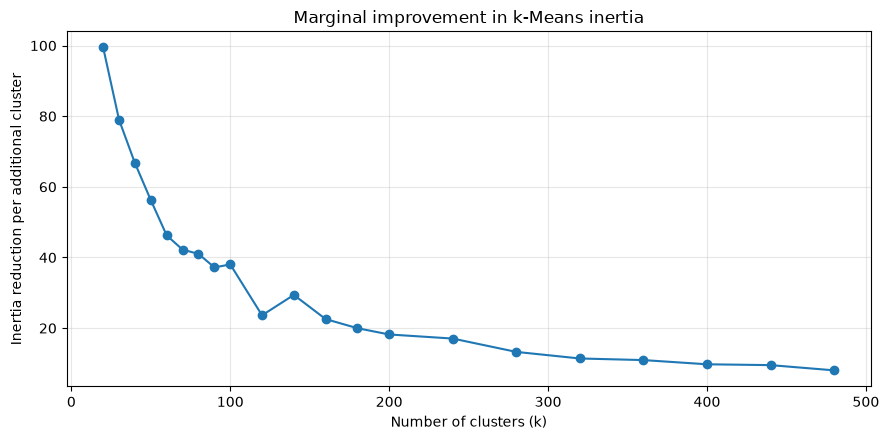

In [6]:
import matplotlib.pyplot as plt

curve = comparison.sort_values("k").copy()

curve["improvement_per_cluster"] = (
    -curve["inertia"].diff() / curve["k"].diff()
)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    curve["k"].iloc[1:],
    curve["improvement_per_cluster"].iloc[1:],
    marker="o"
)

ax.set(
    xlabel="Number of clusters (k)",
    ylabel="Inertia reduction per additional cluster",
    title="Marginal improvement in k-Means inertia"
)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A small inertia improvement at higher k could still correspond to the separation of two scientifically meaningful topics.

We might visually argue that the curve begins flattening somewhere around k = 60–100, but transition is gradual.

## 6. Sampled silhouette evaluation

In [7]:
from sklearn.metrics import silhouette_score

# Fixed random sample, shared across all models
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_tfidf.shape[0],
    size=4000,
    replace=False
)

X_sample = X_tfidf[sample_indices]

k_values = [20, 40, 80, 160, 240]

silhouette_results = []

for k in k_values:
    model = models[k]

    # Labels of sampled documents from the full-data model
    labels_sample = model.labels_[sample_indices]

    # Check how well clusters are represented in the sample
    counts = np.bincount(labels_sample, minlength=k)

    score = silhouette_score(
        X_sample,
        labels_sample,
        metric="euclidean"
    )

    silhouette_results.append({
        "k": k,
        "silhouette": round(score, 4),
        "clusters_represented": np.sum(counts > 0),
        "singleton_clusters": np.sum(counts == 1)
    })

silhouette_comparison = pd.DataFrame(
    silhouette_results
)

display(silhouette_comparison)

,k,silhouette,clusters_represented,singleton_clusters
0,20,0.0082,20,0
1,40,0.0116,40,0
2,80,0.0171,80,0
3,160,0.0229,160,2
4,240,0.0243,239,2


All scores are positive but very low. The score rises from 0.0082 at k = 20 to 0.0243 at k = 240.

The difference between k = 160 and k = 240 is only 0.0014. Without assessing sampling variability, we cannot determine whether that difference represents a meaningful improvement.

At k = 240, 239 of 240 clusters appear in the evaluation sample, and only two sampled clusters contain a single document.

## 7. Qualitative cluster inspection

In [8]:
rng = np.random.default_rng(42)

for k in [40, 160, 240, 480]:
    model = models[k]
    labels = model.labels_
    sizes = np.bincount(labels, minlength=k)

    median_size = np.median(sizes)

    # Select clusters systematically by size
    selected = [
        ("largest", int(np.argmax(sizes))),
        ("median-sized", int(
            np.argmin(np.abs(sizes - median_size))
        ))
    ]

    # Examine possible fragmentation at the finest resolution
    if k == 480:
        selected.append(
            ("smallest", int(np.argmin(sizes)))
        )

    for group_type, c in selected:
        center = model.cluster_centers_[c]
        members = np.flatnonzero(labels == c)

        # Highest-weighted centroid features
        top_idx = np.argsort(center)[-10:][::-1]
        top_terms = feature_names[top_idx]

        # Documents nearest to the centroid
        similarities = np.asarray(
            X_tfidf[members] @ center
        ).ravel()

        representative = members[
            np.argsort(similarities)[-2:][::-1]
        ]

        # Random documents for a less selective inspection
        random_docs = rng.choice(
            members, size=2, replace=False
        )

        print(f"\n{'=' * 65}")
        print(
            f"k={k} | {group_type} cluster {c} "
            f"| {len(members):,} papers"
        )
        print(f"{'=' * 65}")

        print("\nTop centroid terms:")
        print(", ".join(top_terms))

        print("\nRepresentative paper titles:")
        for i in representative:
            print("-", metadata.iloc[i]["clean_title"])

        print("\nRandomly sampled paper titles:")
        for i in random_docs:
            print("-", metadata.iloc[i]["clean_title"])


k=40 | largest cluster 25 | 13,326 papers

Top centroid terms:
language, model, models, text, based, task, learning, data, dataset, using

Representative paper titles:
- From Text to CQL: Bridging Natural Language and Corpus Search Engine
- The Use of NLP-Based Text Representation Techniques to Support Requirement Engineering Tasks: A Systematic Mapping Review

Randomly sampled paper titles:
- A Review of Bangla Natural Language Processing Tasks and the Utility of Transformer Models
- Developing a Modular Compiler for a Subset of a C-like Language

k=40 | median-sized cluster 11 | 1,295 papers

Top centroid terms:
graph, knowledge, knowledge graph, graphs, kg, kgs, knowledge graphs, information, based, text

Representative paper titles:
- Edge: Enriching Knowledge Graph Embeddings with External Text
- Relphormer: Relational Graph Transformer for Knowledge Graph Representations

Randomly sampled paper titles:
- Developing a Scalable Benchmark for Assessing Large Language Models in Know

## 7. Compare cluster cohesion

In [9]:
cohesion_results = []

for k in [40, 160, 240, 480]:
    model = models[k]
    sizes = np.bincount(model.labels_, minlength=k)

    # Norms of cluster centroids
    centroid_norms = np.linalg.norm(
        model.cluster_centers_, axis=1
    )

    largest = np.argmax(sizes)
    median = np.argmin(
        np.abs(sizes - np.median(sizes))
    )

    cohesion_results.append({
        "k": k,
        "median_cohesion": np.median(centroid_norms),
        "weighted_mean_cohesion": np.average(
            centroid_norms, weights=sizes
        ),
        "largest_cluster_cohesion": centroid_norms[largest],
        "median_size_cluster_cohesion": centroid_norms[median]
    })

cohesion_comparison = pd.DataFrame(cohesion_results)

display(cohesion_comparison.round(4))

,k,median_cohesion,weighted_mean_cohesion,largest_cluster_cohesion,median_size_cluster_cohesion
0,40,0.3334,0.2768,0.1484,0.3269
1,160,0.4165,0.3580,0.1402,0.3710
2,240,0.4321,0.3844,0.1460,0.5096
3,480,0.4597,0.4269,0.1399,0.5032


These results reinforce an important finding from our qualitative inspection: increasing the number of clusters improves overall cohesion, but the largest cluster remains consistently diffuse.

Median cohesion rises from 0.3334 at k = 40 to 0.4597 at k = 480. The document-weighted mean also increases. This is consistent with finer partitions grouping more lexically similar documents. However, this improvement is partly expected from increasing model complexity; it does not independently establish that the clusters are scientifically meaningful.

These observations provide a reasone for investigating whether dimensionality reduction could improve the representation used for clustering.

## 8. TruncatedSVD as an alternative representation

Unlike conventional PCA, TruncatedSVD (Truncated Singular Value Decomposition) does not require centering the original sparse matrix. It can therefore work efficiently with our existing representation.

In text analysis, this approach combines patterns of term co-occurrence into a smaller set of latent dimensions and is commonly associated with Latent Semantic Analysis (LSA).

Hypothesis:

Reducing the dimensionality of the TF–IDF representation may suppress some lexical noise and help reveal broader relationships between documents, potentially improving clustering coherence and separation.

There is a trade-off: dimensionality reduction may also discard distinctive vocabulary associated with specialized research areas.

In [10]:
from sklearn.decomposition import TruncatedSVD
from time import perf_counter

# Let's try 100 components as an initial diagnostic choice
svd = TruncatedSVD(
    n_components=100,
    algorithm="randomized",
    random_state=42
)

start = perf_counter()
X_svd = svd.fit_transform(X_tfidf)
elapsed = perf_counter() - start

print("Original shape:", X_tfidf.shape)
print("Reduced shape:", X_svd.shape)
print("Reduced dtype:", X_svd.dtype)
print(f"Fitting time: {elapsed:.2f} seconds")

print(
    "Cumulative explained variance:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

row_norms = np.linalg.norm(X_svd, axis=1)

print(
    "Reduced vector norm percentiles:",
    np.round(
        np.percentile(row_norms, [0, 25, 50, 75, 100]),
        4
    )
)

Original shape: (75110, 10000)
Reduced shape: (75110, 100)
Reduced dtype: float32
Fitting time: 1.92 seconds
Cumulative explained variance: 0.1717
Reduced vector norm percentiles: [0.0579 0.3508 0.4231 0.4995 0.8627]


## 8. Controlled clustering comparison

Testing the reduced representation at k = 160.

K 160 is an intermediate resolution from our earlier exploration, where we observed both recognisable specialised clusters and a large diffuse cluster. It gives a useful comparison point without committing to a final number of themes.

The clustering algorithm and its parameters will remain unchanged. Only the feature representation will differ.

In [11]:
from sklearn.preprocessing import normalize

# Normalize the reduced representation
X_lsa = normalize(X_svd, norm="l2", copy=True)

# Fit KMeans with the same baseline parameters
k_compare = 160

kmeans_lsa = KMeans(
    n_clusters=k_compare,
    init="k-means++",
    n_init=3,
    max_iter=100,
    random_state=42
)

start = perf_counter()
kmeans_lsa.fit(X_lsa)
elapsed = perf_counter() - start

sizes_lsa = np.bincount(
    kmeans_lsa.labels_,
    minlength=k_compare
)

print(f"Fitting time: {elapsed:.2f} seconds")
print("Iterations:", kmeans_lsa.n_iter_)
print("Smallest cluster:", sizes_lsa.min())
print("Median cluster:", np.median(sizes_lsa))
print(
    "Largest cluster share:",
    f"{sizes_lsa.max() / X_lsa.shape[0]:.2%}"
)

Fitting time: 4.28 seconds
Iterations: 77
Smallest cluster: 150
Median cluster: 415.5
Largest cluster share: 1.39%


In [12]:
labels_lsa_sample = kmeans_lsa.labels_[sample_indices]

silhouette_lsa_original = silhouette_score(
    X_tfidf[sample_indices],
    labels_lsa_sample,
    metric="euclidean"
)

print(
    "LSA clustering, evaluated in original TF-IDF space:",
    round(silhouette_lsa_original, 4)
)

print(
    "Original TF-IDF clustering at k=160:",
    0.0229  # Previously observed sampled silhouette
)

LSA clustering, evaluated in original TF-IDF space: 0.0177
Original TF-IDF clustering at k=160: 0.0229


In [13]:
rng = np.random.default_rng(42)

labels = kmeans_lsa.labels_
sizes = np.bincount(labels, minlength=160)

selected = [
    ("largest", int(np.argmax(sizes))),
    ("median-sized", int(
        np.argmin(np.abs(sizes - np.median(sizes)))
    )),
    ("smallest", int(np.argmin(sizes)))
]

for group_type, c in selected:
    members = np.flatnonzero(labels == c)

    # Mean TF-IDF vocabulary weights of cluster members
    mean_tfidf = np.asarray(
        X_tfidf[members].mean(axis=0)
    ).ravel()

    top_idx = np.argsort(mean_tfidf)[-12:][::-1]
    top_terms = feature_names[top_idx]

    # Representative papers in reduced LSA space
    center = kmeans_lsa.cluster_centers_[c]

    similarities = X_lsa[members] @ center

    representative = members[
        np.argsort(similarities)[-3:][::-1]
    ]

    # Independently sampled papers
    random_docs = rng.choice(
        members, size=3, replace=False
    )

    print(f"\n{'=' * 65}")
    print(
        f"{group_type.upper()} CLUSTER {c} "
        f"— {len(members):,} papers"
    )
    print(f"{'=' * 65}")

    print("\nTop original TF-IDF terms:")
    print(", ".join(top_terms))

    print("\nRepresentative paper titles:")
    for i in representative:
        print("-", metadata.iloc[i]["clean_title"])

    print("\nRandomly sampled paper titles:")
    for i in random_docs:
        print("-", metadata.iloc[i]["clean_title"])


LARGEST CLUSTER 52 — 1,042 papers

Top original TF-IDF terms:
bias, gender, biases, gender bias, models, llms, fairness, language, debiasing, social, biased, language models

Representative paper titles:
- JobFair: A Framework for Benchmarking Gender Hiring Bias in Large Language Models
- Protected group bias and stereotypes in Large Language Models
- Blind Men and the Elephant: Diverse Perspectives on Gender Stereotypes in Benchmark Datasets

Randomly sampled paper titles:
- Biased or Flawed? Mitigating Stereotypes in Generative Language Models by Addressing Task-Specific Flaws
- Few-shot Instruction Prompts for Pretrained Language Models to Detect Social Biases
- Beyond Early-Token Bias: Model-Specific and Language-Specific Position Effects in Multilingual LLMs

MEDIAN-SIZED CLUSTER 51 — 417 papers

Top original TF-IDF terms:
questions, question, answer, answers, question generation, generation, answering, reading, llms, comprehension, models, multiple choice

Representative paper t

In [14]:
# Original large, generic TF-IDF cluster at k=160
source_cluster = 88

original_labels = models[160].labels_
lsa_labels = kmeans_lsa.labels_

source_indices = np.flatnonzero(
    original_labels == source_cluster
)

# Count where these papers were assigned by LSA
counts = np.bincount(
    lsa_labels[source_indices],
    minlength=160
)

top_destinations = np.argsort(counts)[-5:][::-1]

print("Original cluster size:", len(source_indices))
print("LSA clusters receiving these papers:", np.sum(counts > 0))

rng = np.random.default_rng(42)

for c in top_destinations:
    members = source_indices[
        lsa_labels[source_indices] == c
    ]

    # Overall size of the destination LSA cluster
    destination_size = np.sum(lsa_labels == c)

    # Vocabulary of the transferred papers
    mean_tfidf = np.asarray(
        X_tfidf[members].mean(axis=0)
    ).ravel()

    top_idx = np.argsort(mean_tfidf)[-10:][::-1]

    random_docs = rng.choice(
        members, size=min(3, len(members)), replace=False
    )

    print(f"\n{'=' * 60}")
    print(f"Destination LSA cluster: {c}")
    print(f"Papers from original cluster: {len(members)}")
    print(f"Share of original cluster: {len(members)/len(source_indices):.1%}")
    print(f"Share of destination cluster: {len(members)/destination_size:.1%}")

    print("\nTop terms:")
    print(", ".join(feature_names[top_idx]))

    print("\nSample paper titles:")
    for i in random_docs:
        print("-", metadata.iloc[i]["clean_title"])

Original cluster size: 5312
LSA clusters receiving these papers: 160

Destination LSA cluster: 21
Papers from original cluster: 350
Share of original cluster: 6.6%
Share of destination cluster: 76.8%

Top terms:
linguistic, analysis, study, corpus, computational, discourse, research, features, texts, information

Sample paper titles:
- Accurate and Data-Efficient Toxicity Prediction when Annotators Disagree
- Idiosyncratic but not Arbitrary: Learning Idiolects in Online Registers Reveals Distinctive yet Consistent Individual Styles
- Psycholinguistic Analyses in Software Engineering Text: A Systematic Literature Review

Destination LSA cluster: 99
Papers from original cluster: 246
Share of original cluster: 4.6%
Share of destination cluster: 36.2%

Top terms:
generation, text generation, text, control, model, story, language, controllable, generate, generated

Sample paper titles:
- COINS: Dynamically Generating COntextualized Inference Rules for Narrative Story Completion
- Contextual

We should investigate less aggressive dimensionality reduction before deciding whether TruncatedSVD improves clustering.

The original TF–IDF cluster contained 5,312 papers. After LSA clustering at k = 160:
- Its documents were distributed across all 160 LSA clusters.
- The five largest destinations received 1,168 papers, approximately 22% of the original cluster.
- Some destinations have recognizable thematic characteristics, but others remain heterogeneous.
For example, destination cluster 99 focuses on text generation, and cluster 24 contains vocabulary associated with grammars and formal structures. However, cluster 119 remains broadly defined by datasets and corpora, while cluster 114 combines potentially different approaches to text processing.

Interpretation: LSA did not simply preserve the original generic cluster. It redistributed its documents into many smaller groups, some of which appear more interpretable.

Nevertheless, this redistribution alone does not establish improved clustering quality. Some destination clusters still contain papers that appear only loosely related.

## 9. Investigate explained variance at 200 and 500 components

In [15]:
import gc
from sklearn.decomposition import TruncatedSVD
from time import perf_counter

# Include the previously fitted 100-component model
svd_results = [{
    "components": 100,
    "explained_variance": svd.explained_variance_ratio_.sum(),
    "fit_time_s": 1.92  # Previously recorded
}]

for n in [200, 500]:
    reducer = TruncatedSVD(
        n_components=n,
        algorithm="randomized",
        n_iter=5,
        random_state=42
    )

    start = perf_counter()
    reducer.fit(X_tfidf)
    elapsed = perf_counter() - start

    explained = reducer.explained_variance_ratio_.sum()

    svd_results.append({
        "components": n,
        "explained_variance": explained,
        "fit_time_s": round(elapsed, 2)
    })

    print(
        f"{n} components | "
        f"Explained variance: {explained:.2%} | "
        f"Time: {elapsed:.2f}s"
    )

    # Release each fitted model after recording its diagnostics
    del reducer
    gc.collect()

svd_comparison = pd.DataFrame(svd_results)

display(svd_comparison)

200 components | Explained variance: 24.91% | Time: 3.11s
500 components | Explained variance: 38.26% | Time: 8.65s


,components,explained_variance,fit_time_s
0,100,0.171699,1.92
1,200,0.249107,3.11
2,500,0.382635,8.65


In [16]:
svd_1000 = TruncatedSVD(
    n_components=1000,
    algorithm="randomized",
    n_iter=5,
    random_state=42
)

start = perf_counter()
svd_1000.fit(X_tfidf)
elapsed = perf_counter() - start

variance_1000 = svd_1000.explained_variance_ratio_.sum()

print("Components:", 1000)
print(f"Explained variance: {variance_1000:.2%}")
print(f"Fitting time: {elapsed:.2f} seconds")

Components: 1000
Explained variance: 51.38%
Fitting time: 19.24 seconds


Moving from 500 to 1,000 components increases explained variance by another 13.12 percentage points. However, it requires 500 additional dimensions, compared with the 300 dimensions needed to move from 200 to 500 components.

In [17]:
#Clustering with 500 SVD components
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from time import perf_counter

# Build the 500-component representation
svd_500 = TruncatedSVD(
    n_components=500,
    algorithm="randomized",
    n_iter=5,
    random_state=42
)

X_lsa_500 = svd_500.fit_transform(X_tfidf)
X_lsa_500 = normalize(X_lsa_500, norm="l2", copy=False)

# Fit KMeans using the same settings
kmeans_lsa_500 = KMeans(
    n_clusters=160,
    init="k-means++",
    n_init=3,
    max_iter=100,
    random_state=42
)

start = perf_counter()
kmeans_lsa_500.fit(X_lsa_500)
fit_time = perf_counter() - start

sizes_500 = np.bincount(
    kmeans_lsa_500.labels_,
    minlength=160
)

print(f"Clustering time: {fit_time:.2f} seconds")
print("Iterations:", kmeans_lsa_500.n_iter_)
print("Smallest cluster:", sizes_500.min())
print("Median cluster:", np.median(sizes_500))
print(
    "Largest cluster share:",
    f"{sizes_500.max() / len(metadata):.2%}"
)

Clustering time: 17.56 seconds
Iterations: 100
Smallest cluster: 120
Median cluster: 390.0
Largest cluster share: 3.95%


In [18]:
from sklearn.metrics import silhouette_score

score_500 = silhouette_score(
    X_tfidf[sample_indices],
    kmeans_lsa_500.labels_[sample_indices],
    metric="euclidean"
)

print("Original TF-IDF:", 0.0229)
print("LSA 100 components:", 0.0177)
print("LSA 500 components:", round(score_500, 4))

Original TF-IDF: 0.0229
LSA 100 components: 0.0177
LSA 500 components: 0.0237


We hit the iteration limit of 100 with 500 componenets.

In [19]:
# Check convergence with a higher iteration limit
from sklearn.metrics import adjusted_rand_score

kmeans_lsa_500_refined = KMeans(
    n_clusters=160,
    init="k-means++",
    n_init=3,
    max_iter=300,
    random_state=42
)

start = perf_counter()
kmeans_lsa_500_refined.fit(X_lsa_500)
elapsed = perf_counter() - start

# Compare with the earlier 100-iteration model
score_refined = silhouette_score(
    X_tfidf[sample_indices],
    kmeans_lsa_500_refined.labels_[sample_indices],
    metric="euclidean"
)

agreement = adjusted_rand_score(
    kmeans_lsa_500.labels_,
    kmeans_lsa_500_refined.labels_
)

sizes_refined = np.bincount(
    kmeans_lsa_500_refined.labels_,
    minlength=160
)

print(f"Fitting time: {elapsed:.2f} seconds")
print("Iterations:", kmeans_lsa_500_refined.n_iter_)

print("\nInertia in LSA space:")
print("Original:", round(kmeans_lsa_500.inertia_, 2))
print("Refined:", round(kmeans_lsa_500_refined.inertia_, 2))

print("\nOriginal-space silhouette:")
print("Original:", 0.0237)
print("Refined:", round(score_refined, 4))

print("\nLargest cluster share:",
      f"{sizes_refined.max() / len(metadata):.2%}")

print("Adjusted Rand Index:", round(agreement, 4))

Fitting time: 17.62 seconds
Iterations: 118

Inertia in LSA space:
Original: 50054.57
Refined: 50053.37

Original-space silhouette:
Original: 0.0237
Refined: 0.0237

Largest cluster share: 4.08%
Adjusted Rand Index: 0.9792


In [20]:
rng = np.random.default_rng(42)

model = kmeans_lsa_500_refined
labels = model.labels_
sizes = np.bincount(labels, minlength=160)

selected = [
    ("largest", int(np.argmax(sizes))),
    ("median-sized", int(
        np.argmin(np.abs(sizes - np.median(sizes)))
    )),
    ("smallest", int(np.argmin(sizes)))
]

for group_type, c in selected:
    members = np.flatnonzero(labels == c)

    # Characterize cluster using original TF-IDF vocabulary
    mean_tfidf = np.asarray(
        X_tfidf[members].mean(axis=0)
    ).ravel()

    top_idx = np.argsort(mean_tfidf)[-12:][::-1]
    top_terms = feature_names[top_idx]

    # Representative papers in normalized LSA space
    center = model.cluster_centers_[c]

    similarities = X_lsa_500[members] @ center

    representative = members[
        np.argsort(similarities)[-3:][::-1]
    ]

    # Random papers for less selective inspection
    random_docs = rng.choice(
        members, size=3, replace=False
    )

    print(f"\n{'=' * 65}")
    print(
        f"{group_type.upper()} CLUSTER {c} "
        f"— {len(members):,} papers"
    )
    print(f"{'=' * 65}")

    print("\nTop original TF-IDF terms:")
    print(", ".join(top_terms))

    print("\nRepresentative paper titles:")
    for i in representative:
        print("-", metadata.iloc[i]["clean_title"])

    print("\nRandomly sampled paper titles:")
    for i in random_docs:
        print("-", metadata.iloc[i]["clean_title"])


LARGEST CLUSTER 5 — 3,068 papers

Top original TF-IDF terms:
language, learning, based, model, dataset, text, data, models, using, corpus, analysis, research

Representative paper titles:
- Hype or not? Formalizing Automatic Promotional Language Detection in Biomedical Research
- Conjunct Resolution in the Face of Verbal Omissions
- AIMS.au: A Dataset for the Analysis of Modern Slavery Countermeasures in Corporate Statements

Randomly sampled paper titles:
- Let Guidelines Guide You: A Prescriptive Guideline-Centered Data Annotation Methodology
- Grammar Equations
- Stylomech: Unveiling Authorship via Computational Stylometry in English and Romanized Sinhala

MEDIAN-SIZED CLUSTER 124 — 395 papers

Top original TF-IDF terms:
parsing, semantic parsing, dependency, semantic, parser, parsers, amr, dependency parsing, syntactic, constituency, parse, based

Representative paper titles:
- On the Challenges of Fully Incremental Neural Dependency Parsing
- Integrating Supertag Features into Ne

LSA with 500 components produces some clearly interpretable research themes, but the large, heterogeneous cluster we observed with direct TF–IDF clustering has reappeared.

This suggests that increasing the number of retained components does not necessarily improve the scientific usefulness of the clusters, even when silhouette scores increase.

In [21]:
# Fit and normalize the 200-component representation
svd_200 = TruncatedSVD(
    n_components=200,
    algorithm="randomized",
    n_iter=5,
    random_state=42
)

X_lsa_200 = normalize(
    svd_200.fit_transform(X_tfidf),
    norm="l2",
    copy=False
)

# Fit k-Means
kmeans_lsa_200 = KMeans(
    n_clusters=160,
    init="k-means++",
    n_init=3,
    max_iter=300,
    random_state=42
)

start = perf_counter()
kmeans_lsa_200.fit(X_lsa_200)
elapsed = perf_counter() - start

sizes_200 = np.bincount(
    kmeans_lsa_200.labels_,
    minlength=160
)

# Evaluate in original TF-IDF space
score_200 = silhouette_score(
    X_tfidf[sample_indices],
    kmeans_lsa_200.labels_[sample_indices],
    metric="euclidean"
)

print(f"Clustering time: {elapsed:.2f} seconds")
print("Iterations:", kmeans_lsa_200.n_iter_)
print("Smallest cluster:", sizes_200.min())
print("Median cluster:", np.median(sizes_200))
print("Largest cluster:", sizes_200.max())
print(
    "Largest cluster share:",
    f"{sizes_200.max() / len(metadata):.2%}"
)
print("Original-space silhouette:", round(score_200, 4))

Clustering time: 7.46 seconds
Iterations: 76
Smallest cluster: 144
Median cluster: 420.0
Largest cluster: 1358
Largest cluster share: 1.81%
Original-space silhouette: 0.0227


In [22]:
rng = np.random.default_rng(42)

labels = kmeans_lsa_200.labels_
largest_cluster = np.argmax(sizes_200)

members = np.flatnonzero(
    labels == largest_cluster
)

# Original vocabulary representation
mean_tfidf = np.asarray(
    X_tfidf[members].mean(axis=0)
).ravel()

top_idx = np.argsort(mean_tfidf)[-12:][::-1]

# Representative papers in LSA space
center = kmeans_lsa_200.cluster_centers_[largest_cluster]

similarities = X_lsa_200[members] @ center

representative = members[
    np.argsort(similarities)[-3:][::-1]
]

# Random papers
random_docs = rng.choice(
    members, size=5, replace=False
)

print(f"Largest cluster: {largest_cluster}")
print(f"Papers: {len(members):,}")

print("\nTop terms:")
print(", ".join(feature_names[top_idx]))

print("\nRepresentative papers:")
for i in representative:
    print("-", metadata.iloc[i]["clean_title"])

print("\nRandomly sampled papers:")
for i in random_docs:
    print("-", metadata.iloc[i]["clean_title"])

Largest cluster: 27
Papers: 1,358

Top terms:
reasoning, llms, models, logical, language, tasks, large, language models, reasoning tasks, capabilities, thinking, reasoning models

Representative papers:
- DetermLR: Augmenting LLM-based Logical Reasoning from Indeterminacy to Determinacy
- Reasoning on a Spectrum: Aligning LLMs to System 1 and System 2 Thinking
- Algorithmic Thinking Theory

Randomly sampled papers:
- ReaLM: Reflection-Enhanced Autonomous Reasoning with Small Language Models
- L1: Controlling How Long A Reasoning Model Thinks With Reinforcement Learning
- More or Less Wrong: A Benchmark for Directional Bias in LLM Comparative Reasoning
- On The Role of Reasoning in the Identification of Subtle Stereotypes in Natural Language
- EnigmaToM: Improve LLMs' Theory-of-Mind Reasoning Capabilities with Neural Knowledge Base of Entity States


In [23]:
# Inspect LSA 200

rng = np.random.default_rng(42)

model = kmeans_lsa_200
labels = model.labels_

# Randomly select five distinct clusters
selected_clusters = rng.choice(
    model.n_clusters,
    size=5,
    replace=False
)

for c in selected_clusters:
    members = np.flatnonzero(labels == c)

    # Describe the cluster using original vocabulary
    mean_tfidf = np.asarray(
        X_tfidf[members].mean(axis=0)
    ).ravel()

    top_idx = np.argsort(mean_tfidf)[-10:][::-1]

    # Find two centroid-nearest publications
    center = model.cluster_centers_[c]
    similarities = X_lsa_200[members] @ center

    representative = members[
        np.argsort(similarities)[-2:][::-1]
    ]

    # Three randomly selected publications
    random_docs = rng.choice(
        members, size=3, replace=False
    )

    print(f"\n{'=' * 65}")
    print(f"CLUSTER {c} — {len(members):,} papers")
    print(f"{'=' * 65}")

    print("\nTop terms:")
    print(", ".join(feature_names[top_idx]))

    print("\nRepresentative titles:")
    for i in representative:
        print("-", metadata.iloc[i]["clean_title"])

    print("\nRandom titles:")
    for i in random_docs:
        print("-", metadata.iloc[i]["clean_title"])


CLUSTER 121 — 355 papers

Top terms:
audio, speech, audio visual, music, text, audio language, visual, lalms, models, model

Representative titles:
- Kimi-Audio Technical Report
- SeaLLMs-Audio: Large Audio-Language Models for Southeast Asia

Random titles:
- Visualizations of Complex Sequences of Family-Infant Vocalizations Using Bag-of-Audio-Words Approach Based on Wav2vec 2.0 Features
- ASI-Seg: Audio-Driven Surgical Instrument Segmentation with Surgeon Intention Understanding
- ORCA: Open-ended Response Correctness Assessment for Audio Question Answering

CLUSTER 69 — 572 papers

Top terms:
question, answering, question answering, answer, questions, vqa, answers, knowledge, visual question, dataset

Representative titles:
- Building a Question Answering System for the Manufacturing Domain
- Interactive Question Answering Systems: Literature Review

Random titles:
- WebGLM: Towards An Efficient Web-Enhanced Question Answering System with Human Preferences
- Unlocking Markets: A Mul

In [24]:
# Inspect the weakest LSA 200 clusters

model = kmeans_lsa_200
labels = model.labels_

# Cohesion within the normalized LSA space
centroid_norms = np.linalg.norm(
    model.cluster_centers_, axis=1
)

# Three least cohesive clusters
weakest_clusters = np.argsort(centroid_norms)[:3]

rng = np.random.default_rng(42)

for c in weakest_clusters:
    members = np.flatnonzero(labels == c)

    # Mean original TF-IDF vocabulary weights
    mean_tfidf = np.asarray(
        X_tfidf[members].mean(axis=0)
    ).ravel()

    top_idx = np.argsort(mean_tfidf)[-10:][::-1]

    # Representative documents in normalized LSA space
    center = model.cluster_centers_[c]
    similarities = X_lsa_200[members] @ center

    representative = members[
        np.argsort(similarities)[-2:][::-1]
    ]

    random_docs = rng.choice(
        members, size=3, replace=False
    )

    print(f"\n{'=' * 65}")
    print(f"CLUSTER {c} — {len(members):,} papers")
    print(f"Centroid norm: {centroid_norms[c]:.4f}")
    print(f"{'=' * 65}")

    print("\nTop terms:")
    print(", ".join(feature_names[top_idx]))

    print("\nRepresentative titles:")
    for i in representative:
        print("-", metadata.iloc[i]["clean_title"])

    print("\nRandom titles:")
    for i in random_docs:
        print("-", metadata.iloc[i]["clean_title"])


CLUSTER 12 — 953 papers
Centroid norm: 0.4518

Top terms:
linguistic, features, uncertainty, based, research, text, model, language, analysis, review

Representative titles:
- Quantification of Tenseness in English and Japanese Tense-Lax Vowels: A Lagrangian Model with Indicator {\theta}1 and Force of Tenseness Ftense(t)
- From exemplar to copy: the scribal appropriation of a Hadewijch manuscript computationally explored

Random titles:
- Generalized Measures of Anticipation and Responsivity in Online Language Processing
- Lemmatization of Historical Old Literary Finnish Texts in Modern Orthography
- Figurative Archive: an open dataset and web-based application for the study of metaphor

CLUSTER 5 — 765 papers
Centroid norm: 0.5740

Top terms:
models, model, language, language models, training, large, large language, language model, performance, open

Representative titles:
- MindLLM: Pre-training Lightweight Large Language Model from Scratch, Evaluations and Domain Applications
- Pan

## 10. Revisiting the optimal k to provide the right thematic granularity

Original TF–IDF experiments showed no clear elbow, and sampled silhouette increased gradually with k. Therefore, we should not expect a single numerical criterion to identify an objectively optimal cluster count.

Let's compare a limited range using the same LSA 200 representation.

In [25]:
k_values = [40, 80, 120, 160, 240]

# Reuse the existing k=160 model
lsa200_models = {160: kmeans_lsa_200}

X_sample_lsa = X_lsa_200[sample_indices]
X_sample_original = X_tfidf[sample_indices]

results = []

for k in k_values:

    if k not in lsa200_models:
        candidate = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=3,
            max_iter=300,
            random_state=42
        )
        candidate.fit(X_lsa_200)
        lsa200_models[k] = candidate

    model = lsa200_models[k]
    sizes = np.bincount(model.labels_, minlength=k)
    sample_labels = model.labels_[sample_indices]

    results.append({
        "k": k,
        "iterations": model.n_iter_,
        "inertia": model.inertia_,
        "silhouette_lsa": silhouette_score(
            X_sample_lsa,
            sample_labels,
            metric="euclidean"
        ),
        "silhouette_original": silhouette_score(
            X_sample_original,
            sample_labels,
            metric="euclidean"
        ),
        "median_size": np.median(sizes),
        "largest_pct": 100 * sizes.max() / len(metadata),
        "min_centroid_norm": np.linalg.norm(
            model.cluster_centers_, axis=1
        ).min()
    })

k_diagnostics = pd.DataFrame(results)

display(k_diagnostics.round(4))

,k,iterations,inertia,silhouette_lsa,silhouette_original,median_size,largest_pct,min_centroid_norm
0,40,67,52200.2812,0.0566,0.0124,1604.0,10.5365,0.3278
1,80,81,45939.2266,0.0867,0.0190,834.5,5.5785,0.3875
2,120,64,41838.3984,0.1014,0.0227,568.5,2.3592,0.4357
3,160,76,39354.1016,0.1030,0.0227,420.0,1.8080,0.4518
4,240,56,37034.0469,0.0888,0.0206,289.0,1.2582,0.5569


The strongest candidates are k = 120 and k = 160. Both provide substantially better separation than k = 40 or 80, while increasing to k = 240 appears to fragment the representation without improving the overall silhouette.

Our goal is not merely to partition 75,110 documents. We want to identify meaningful NLP research directions and subsequently examine how they evolved from 2021 to 2025.

In [26]:
# Compare the same research themes at k = 120 and 160

model_120 = lsa200_models[120]
model_160 = lsa200_models[160]

themes_160 = {
    13: "Summarization",
    159: "Machine translation",
    69: "Question answering",
    27: "LLM reasoning",
    121: "Audio-language",
    103: "Speech recognition"
}

rows = []

for c160, theme in themes_160.items():

    # Documents belonging to this k=160 cluster
    members_160 = np.flatnonzero(
        model_160.labels_ == c160
    )

    # Their assignments under k=120
    counts = np.bincount(
        model_120.labels_[members_160],
        minlength=120
    )

    c120 = int(np.argmax(counts))
    overlap = int(counts[c120])

    # All papers in the corresponding k=120 cluster
    members_120 = np.flatnonzero(
        model_120.labels_ == c120
    )

    mean_tfidf = np.asarray(
        X_tfidf[members_120].mean(axis=0)
    ).ravel()

    top_idx = np.argsort(mean_tfidf)[-8:][::-1]

    rows.append({
        "theme_at_k160": theme,
        "cluster_160": c160,
        "cluster_120": c120,
        "share_of_160_retained": round(
            overlap / len(members_160), 3
        ),
        "share_of_120_from_theme": round(
            overlap / len(members_120), 3
        ),
        "top_terms_at_k120": ", ".join(
            feature_names[top_idx]
        )
    })

resolution_comparison = pd.DataFrame(rows)

display(resolution_comparison)

,theme_at_k160,cluster_160,cluster_120,share_of_160_retained,share_of_120_from_theme,top_terms_at_k120
0,Summarization,13,72,0.974,0.916,"summarization, summaries, abstractive, summary..."
1,Machine translation,159,21,0.911,0.453,"translation, machine translation, machine, mt,..."
2,Question answering,69,93,0.823,0.371,"question, questions, answering, question answe..."
3,LLM reasoning,27,36,0.959,0.834,"reasoning, llms, models, logical, language, ta..."
4,Audio-language,121,106,0.975,0.956,"audio, speech, music, audio visual, text, visu..."
5,Speech recognition,103,13,0.924,0.851,"end, end end, speech, model, e2e, recognition,..."


Evidence indicates that k = 160 provides a reasonable compromise:
- Its LSA-space silhouette of 0.1030 is slightly higher than the 0.1014 obtained at k = 120.
- The largest cluster contains only 1.81% of the corpus.
- Several randomly sampled clusters have recognizable research themes.
- Some research areas remain more distinct than at k = 120.
- Increasing to k = 240 reduces the sampled silhouette.

# 11. Final validation: stability across random initialisations

In [27]:
from sklearn.metrics import adjusted_rand_score
from time import perf_counter

baseline = lsa200_models[160]

stability_results = [{
    "seed": 42,
    "iterations": baseline.n_iter_,
    "inertia": baseline.inertia_,
    "ARI_vs_baseline": 1.0,
    "largest_pct": (
        100 * np.bincount(baseline.labels_).max()
        / X_lsa_200.shape[0]
    )
}]

for seed in [7, 123, 2025]:
    candidate = KMeans(
        n_clusters=160,
        init="k-means++",
        n_init=3,
        max_iter=300,
        random_state=seed
    )

    start = perf_counter()
    candidate.fit(X_lsa_200)
    elapsed = perf_counter() - start

    ari = adjusted_rand_score(
        baseline.labels_,
        candidate.labels_
    )

    sizes = np.bincount(
        candidate.labels_,
        minlength=160
    )

    stability_results.append({
        "seed": seed,
        "iterations": candidate.n_iter_,
        "inertia": candidate.inertia_,
        "ARI_vs_baseline": ari,
        "largest_pct": 100 * sizes.max() / len(metadata)
    })

    print(
        f"Seed {seed}: "
        f"ARI = {ari:.4f}, "
        f"fit time = {elapsed:.2f}s"
    )

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

Seed 7: ARI = 0.7671, fit time = 7.03s
Seed 123: ARI = 0.7845, fit time = 6.73s
Seed 2025: ARI = 0.7352, fit time = 6.80s


,seed,iterations,inertia,ARI_vs_baseline,largest_pct
0,42,76,39354.1016,1.0000,1.8080
1,7,49,39397.3594,0.7671,1.5670
2,123,41,39380.5625,0.7845,1.8546
3,2025,48,39399.6484,0.7352,1.8466


# 12. Test whether more initialisations improve reproducibility

In [28]:
from itertools import combinations
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from time import perf_counter

robust_models = {}
robust_results = []

for seed in [42, 7, 123]:

    model = KMeans(
        n_clusters=160,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=seed
    )

    start = perf_counter()
    model.fit(X_lsa_200)
    elapsed = perf_counter() - start

    robust_models[seed] = model

    robust_results.append({
        "seed": seed,
        "inertia": model.inertia_,
        "iterations": model.n_iter_,
        "fit_time_s": round(elapsed, 2),
        "ARI_vs_old_baseline": adjusted_rand_score(
            kmeans_lsa_200.labels_,
            model.labels_
        )
    })

display(pd.DataFrame(robust_results).round(4))

print("\nPairwise ARI among n_init=10 runs:")

for a, b in combinations(robust_models, 2):
    ari = adjusted_rand_score(
        robust_models[a].labels_,
        robust_models[b].labels_
    )
    print(f"Seeds {a} vs {b}: {ari:.4f}")

,seed,inertia,iterations,fit_time_s,ARI_vs_old_baseline
0,42,39327.4492,33,23.68,0.7471
1,7,39336.2773,50,23.96,0.7840
2,123,39375.9844,101,25.53,0.7846



Pairwise ARI among n_init=10 runs:
Seeds 42 vs 7: 0.7575
Seeds 42 vs 123: 0.7469
Seeds 7 vs 123: 0.7457


The results indicate that increasing n_init from 3 to 10 has not demonstrably improved the reproducibility of our clustering solution.